**Langkah 1: Persiapan Lingkungan dan Impor Pustaka**

In [8]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy import stats

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

**Langkah 2: Unggah Berkas Data**

In [9]:
from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses 3 TIC).xlsx to Blank Quiz (Responses 3 TIC) (1).xlsx
File terbaca: Blank Quiz (Responses 3 TIC) (1).xlsx


**Langkah 3: Membaca Data dan Memisahkan Butir**

In [10]:
JUMLAH_KOLOM_DEMOGRAFI = 5      # Timestamp, Kelas, Jenis Kelamin, Platform rutin, Platform premium

df = pd.read_excel(nama_file)
demografi = df.iloc[:, :JUMLAH_KOLOM_DEMOGRAFI]
sisa = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

# Hanya kolom berformat "Dimensi [pernyataan]" yang merupakan butir Likert.
kolom_likert = [k for k in sisa.columns if "[" in k]
kolom_lain = [k for k in sisa.columns if "[" not in k]
butir = df[kolom_likert]

print("Jumlah responden (n) :", len(df))
print("Jumlah butir Likert  :", len(kolom_likert))
print("Kolom non-Likert     :", kolom_lain)
print("Data kosong          :", int(butir.isna().sum().sum()))

Jumlah responden (n) : 40
Jumlah butir Likert  : 29
Kolom non-Likert     : ['Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan ']
Data kosong          : 0


**Langkah 4: Mengubah Jawaban Likert Menjadi Angka**

In [11]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Sangat Tidak Setuju (STJ)": 1,   # penulisan di data Google Form
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))
print("Sel gagal dikonversi :", int(num.isna().sum().sum()), "(harus 0)")

Sel gagal dikonversi : 0 (harus 0)


**Langkah 5: Mengelompokkan Butir per Dimensi, Topik dan Kode P**

In [13]:
def nama_dimensi(kolom):
    return re.match(r"^(.*?) \[", kolom).group(1).strip().rstrip(".")

def teks_butir(kolom):
    return re.search(r"\[(.*)\]", kolom, re.S).group(1).strip()

dimensi = {}
for k in kolom_likert:
    dimensi.setdefault(nama_dimensi(k), []).append(k)

# Pembagian topik (urutan dimensi sesuai kuesioner)
TOPIK = {
    "Topik 1": ["Penggunaan AI pada tugas atau projek kuliah",
                "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah"],
    "Topik 2": ["Kebiasaan penggunaan teknologi digital",
                "Prokrastinasi akademik",
                "Respon emosional"],
}

baris, data_topik, dim_kode = [], {}, {}
for topik, daftar_dim in TOPIK.items():
    no, kolom_asli, kode_baru = 0, [], []
    dim_kode[topik] = {}
    for dim in daftar_dim:
        dim_kode[topik][dim] = []
        for kolom in dimensi[dim]:
            no += 1
            kode = f"P{no}"
            baris.append({"Topik": topik, "Dimensi": dim, "Kode": kode,
                          "Pernyataan": teks_butir(kolom)})
            kolom_asli.append(kolom); kode_baru.append(kode)
            dim_kode[topik][dim].append(kode)
    data_topik[topik] = num[kolom_asli].set_axis(kode_baru, axis=1)

keterangan = pd.DataFrame(baris)
for topik in TOPIK:
    print(f"\n=== Keterangan butir {topik} ===")
    display(keterangan[keterangan.Topik == topik].drop(columns="Topik")
            .style.hide(axis="index").set_properties(**{"text-align": "left"}))


=== Keterangan butir Topik 1 ===


Dimensi,Kode,Pernyataan
Penggunaan AI pada tugas atau projek kuliah,P1,Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.
Penggunaan AI pada tugas atau projek kuliah,P2,Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.
Penggunaan AI pada tugas atau projek kuliah,P3,Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek
Penggunaan AI pada tugas atau projek kuliah,P4,Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.
Penggunaan AI pada tugas atau projek kuliah,P5,Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.
Penggunaan AI pada tugas atau projek kuliah,P6,Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.
Penggunaan AI pada tugas atau projek kuliah,P7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P8,Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P9,aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P10,Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).



=== Keterangan butir Topik 2 ===


Dimensi,Kode,Pernyataan
Kebiasaan penggunaan teknologi digital,P1,"Saya sering mengerjakan tugas kuliah sambil melakukan aktivitas lain, seperti membuka media sosial atau menonton video"
Kebiasaan penggunaan teknologi digital,P2,Saya sering memeriksa notifikasi smartphone meskipun sedang mengerjakan tugas kuliah.
Kebiasaan penggunaan teknologi digital,P3,Saya sering menunda pengerjaan tugas karena lebih tertarik menggunakan gadget untuk kegiatan lain yang tidak berhubungan dengan tugas yang sedang saya kerjakan
Kebiasaan penggunaan teknologi digital,P4,"Saya merasa menggunakan AI tidak membutuhkan tingkat konsentrasi yang tinggi, sehingga dapat dikerjakan bersamaan dengan kegiatan yang lain."
Kebiasaan penggunaan teknologi digital,P5,Saya tidak mengkhawatirkan hasil yang diberikan AI
Kebiasaan penggunaan teknologi digital,P6,Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.
Prokrastinasi akademik,P7,Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.
Prokrastinasi akademik,P8,Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI
Prokrastinasi akademik,P9,Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.
Prokrastinasi akademik,P10,Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.



=== Keterangan butir Topik 1 ===


Dimensi,Kode,Pernyataan
Penggunaan AI pada tugas atau projek kuliah,P1,Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.
Penggunaan AI pada tugas atau projek kuliah,P2,Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.
Penggunaan AI pada tugas atau projek kuliah,P3,Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek
Penggunaan AI pada tugas atau projek kuliah,P4,Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.
Penggunaan AI pada tugas atau projek kuliah,P5,Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.
Penggunaan AI pada tugas atau projek kuliah,P6,Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.
Penggunaan AI pada tugas atau projek kuliah,P7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P8,Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P9,aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P10,Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).



=== Keterangan butir Topik 2 ===


Dimensi,Kode,Pernyataan
Kebiasaan penggunaan teknologi digital,P1,"Saya sering mengerjakan tugas kuliah sambil melakukan aktivitas lain, seperti membuka media sosial atau menonton video"
Kebiasaan penggunaan teknologi digital,P2,Saya sering memeriksa notifikasi smartphone meskipun sedang mengerjakan tugas kuliah.
Kebiasaan penggunaan teknologi digital,P3,Saya sering menunda pengerjaan tugas karena lebih tertarik menggunakan gadget untuk kegiatan lain yang tidak berhubungan dengan tugas yang sedang saya kerjakan
Kebiasaan penggunaan teknologi digital,P4,"Saya merasa menggunakan AI tidak membutuhkan tingkat konsentrasi yang tinggi, sehingga dapat dikerjakan bersamaan dengan kegiatan yang lain."
Kebiasaan penggunaan teknologi digital,P5,Saya tidak mengkhawatirkan hasil yang diberikan AI
Kebiasaan penggunaan teknologi digital,P6,Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.
Prokrastinasi akademik,P7,Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.
Prokrastinasi akademik,P8,Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI
Prokrastinasi akademik,P9,Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.
Prokrastinasi akademik,P10,Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.


**Distribusi Data**

Distribusi Jenis Kelamin


,Frekuensi
Jenis Kelamin,
Laki-laki,29
Perempuan,11


Distribusi Durasi Gadget


,Frekuensi
"Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan",
7 - 10 jam,20
4 - 7 jam,15
> 10 jam,5


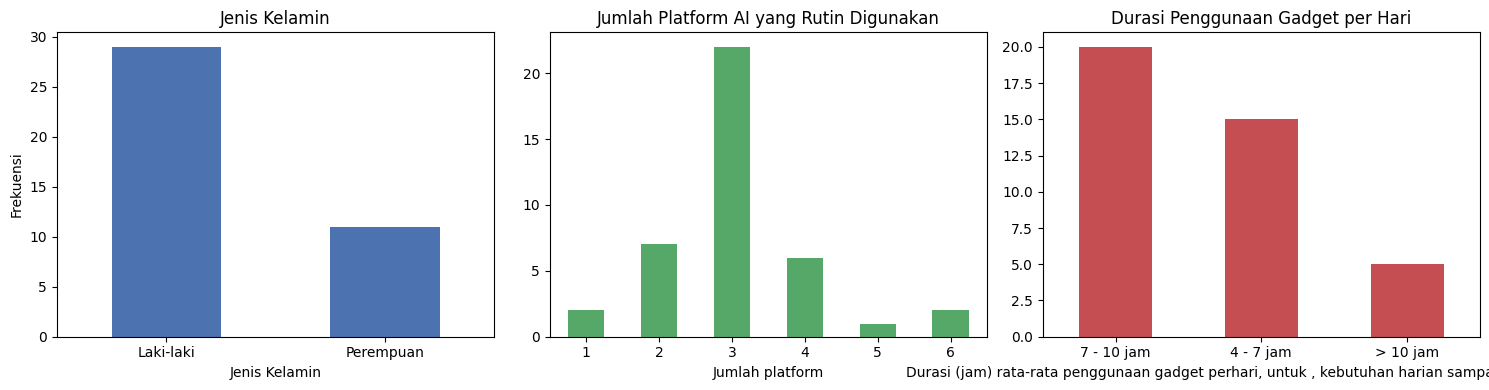


=== Distribusi jawaban Topik 1 (frekuensi) ===


,STS,TS,N,S,SS,Mean,SD
P1,0,1,0,20,19,4.42,0.64
P2,0,0,1,24,15,4.35,0.53
P3,0,3,0,22,15,4.22,0.80
P4,1,7,1,27,4,3.65,0.98
P5,0,7,2,20,11,3.88,1.02
P6,0,3,0,20,17,4.28,0.82
P7,1,1,2,19,17,4.25,0.87
P8,0,3,1,22,14,4.18,0.81
P9,1,10,3,19,7,3.52,1.13
P10,6,15,2,13,4,2.85,1.31


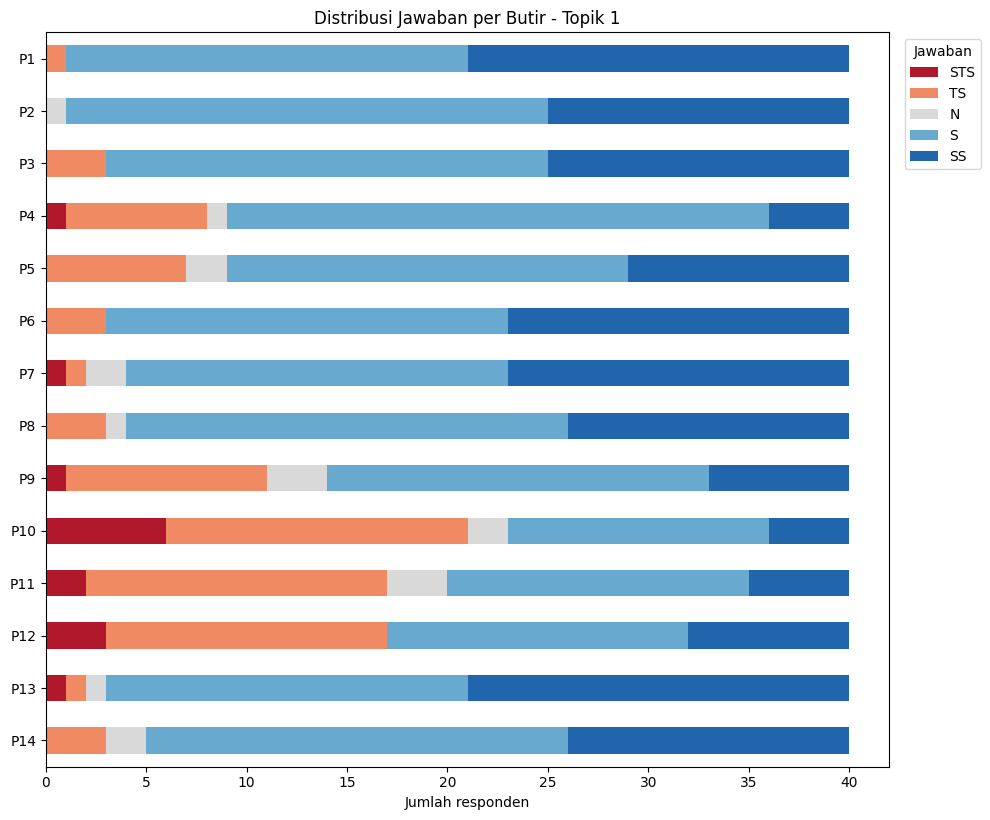


=== Distribusi jawaban Topik 2 (frekuensi) ===


,STS,TS,N,S,SS,Mean,SD
P1,0,7,1,19,13,3.95,1.04
P2,0,5,0,23,12,4.05,0.90
P3,3,11,0,17,9,3.45,1.32
P4,4,14,1,13,8,3.18,1.38
P5,6,15,3,9,7,2.90,1.39
P6,5,21,0,8,6,2.72,1.34
P7,3,14,1,15,7,3.22,1.31
P8,5,14,1,14,6,3.05,1.36
P9,2,14,1,16,7,3.30,1.26
P10,4,9,1,16,10,3.48,1.36


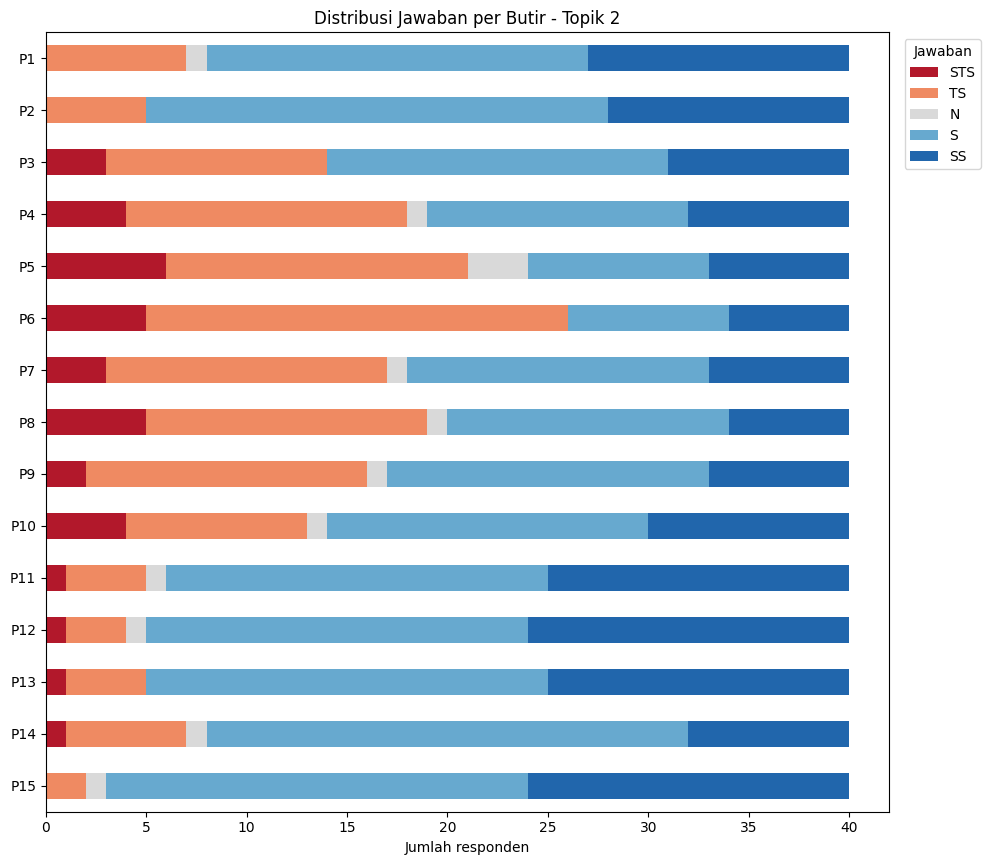

In [17]:
# (a) Data demografi dan data numerik
kol_platform = demografi.columns[3]
kol_premium = demografi.columns[4]
kol_durasi = kolom_lain[0]

print("Distribusi Jenis Kelamin"); display(demografi.iloc[:, 2].value_counts().to_frame("Frekuensi"))
print("Distribusi Durasi Gadget"); display(df[kol_durasi].value_counts().to_frame("Frekuensi"))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
demografi.iloc[:, 2].value_counts().plot.bar(ax=ax[0], color="#4C72B0", rot=0)
ax[0].set_title("Jenis Kelamin"); ax[0].set_ylabel("Frekuensi")
df[kol_platform].value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868", rot=0)
ax[1].set_title("Jumlah Platform AI yang Rutin Digunakan"); ax[1].set_xlabel("Jumlah platform")
df[kol_durasi].value_counts().plot.bar(ax=ax[2], color="#C44E52", rot=0)
ax[2].set_title("Durasi Penggunaan Gadget per Hari")
plt.tight_layout(); plt.show()

# (b) Distribusi jawaban Likert per butir
urutan = ["STS", "TS", "N", "S", "SS"]
nilai_ke_label = {1: "STS", 2: "TS", 3: "N", 4: "S", 5: "SS"}
warna = ["#B2182B", "#EF8A62", "#D9D9D9", "#67A9CF", "#2166AC"]

for topik, data in data_topik.items():
    frek = (data.apply(lambda s: s.map(nilai_ke_label).value_counts())
                .reindex(urutan).fillna(0).astype(int).T)
    frek["Mean"] = data.mean().round(2)
    frek["SD"] = data.std().round(2)
    print(f"\n=== Distribusi jawaban {topik} (frekuensi) ===")

    maks = frek[urutan].values.max()
    gaya_frek = frek.style.format({"Mean": "{:.2f}", "SD": "{:.2f}"})
    pemetaan = gaya_frek.map if hasattr(gaya_frek, "map") else gaya_frek.applymap
    display(pemetaan(lambda v: f"background-color: rgba(33,102,172,{0.05 + 0.6 * v / maks:.2f})",
                     subset=urutan))

    ax = frek[urutan].plot.barh(stacked=True, color=warna, figsize=(10, 0.45 * len(frek) + 2))
    ax.invert_yaxis(); ax.set_xlabel("Jumlah responden")
    ax.set_title(f"Distribusi Jawaban per Butir - {topik}")
    ax.legend(title="Jawaban", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.show()

**r tabel**

In [18]:
n = len(num)
df_bebas = n - 2
t_kritis = stats.t.ppf(0.975, df_bebas)
r_tabel = t_kritis / np.sqrt(df_bebas + t_kritis**2)
print(f"n = {n} | df = n-2 = {df_bebas} | t kritis (a=0,05; dua sisi) = {t_kritis:.4f}")
print(f"r tabel = t / sqrt(df + t^2) = {r_tabel:.3f}")

n = 40 | df = n-2 = 38 | t kritis (a=0,05; dua sisi) = 2.0244
r tabel = t / sqrt(df + t^2) = 0.312


**Langkah 6: Uji Validitas (Korelasi Pearson Butir-Total), Reliabilitas, dan Keputusan**

In [19]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

def keputusan(valid, a_hapus, a_dim):
    if np.isnan(a_hapus):
        return "Pertahankan" if valid else "Tinjau (butir terlalu sedikit)"
    if valid:
        return "Pertahankan" if a_hapus <= a_dim else "Tinjau isi butir"
    return "Hapus" if a_hapus > a_dim else "Ganti pertanyaan"

def analisis(data, kode_dim):
    validitas, reliabilitas = [], []
    for dim, kodes in kode_dim.items():
        x = data[kodes]
        total = x.sum(axis=1)
        a_dim = cronbach_alpha(x)
        reliabilitas.append({"Dimensi": dim, "Jumlah butir": len(kodes),
                             "Cronbach's alpha": a_dim, "Kategori": kategori(a_dim)})
        for k in kodes:
            r, p = stats.pearsonr(x[k], total)
            rc, _ = stats.pearsonr(x[k], total - x[k])
            a_hapus = cronbach_alpha(x.drop(columns=k)) if len(kodes) > 2 else np.nan
            valid = r > r_tabel
            validitas.append({"Dimensi": dim, "Butir": k, "r hitung": r,
                              "r tabel": r_tabel, "Corrected r": rc, "p-value": p,
                              "Validitas": "Valid" if valid else "Tidak valid",
                              "Alpha dimensi": a_dim, "Alpha jika dihapus": a_hapus,
                              "Keputusan": keputusan(valid, a_hapus, a_dim)})
    return pd.DataFrame(validitas), pd.DataFrame(reliabilitas)

def warna_sel(v):
    if v in ("Valid", "Pertahankan", "Sangat baik", "Baik", "Reliabel"):
        return "background-color:#d4edda;color:#155724"
    if v in ("Tidak valid", "Hapus", "Tidak reliabel"):
        return "background-color:#f8d7da;color:#721c24"
    if isinstance(v, str) and (v.startswith("Ganti") or v.startswith("Tinjau")):
        return "background-color:#fff3cd;color:#856404"
    return ""

def gaya(tabel, kolom_warna):
    s = tabel.style.hide(axis="index").format(precision=3, na_rep="-")
    pemetaan = s.map if hasattr(s, "map") else s.applymap
    s = pemetaan(warna_sel, subset=kolom_warna)
    return s.set_table_styles([{"selector": "th", "props": [("background-color", "#2c3e50"),
                                                           ("color", "white"), ("text-align", "center")]}])

**Langkah 7: Jalankan per topik (berulang sampai tidak ada butir yang harus dihapus)**

In [20]:
ringkasan = []

def jalankan_topik(topik):
    data = data_topik[topik].copy()
    kode_dim = {d: list(k) for d, k in dim_kode[topik].items()}
    dibuang, putaran = [], 1
    while True:
        tv, tr = analisis(data, kode_dim)
        print(f"\n{'='*70}\n{topik} - Putaran {putaran}" + (" (data awal)" if putaran == 1 else f" (setelah {dibuang[-1]} dihapus)"))
        print("Uji Validitas:")
        display(gaya(tv, ["Validitas", "Keputusan"]))
        print("Uji Reliabilitas:")
        display(gaya(tr, ["Kategori"]))
        if putaran == 1:
            tv_awal, tr_awal = tv.copy(), tr.copy()
        kandidat = tv[tv["Keputusan"] == "Hapus"]
        if kandidat.empty:
            break
        # hapus satu butir per putaran (r hitung paling rendah), lalu uji ulang
        b = kandidat.sort_values("r hitung").iloc[0]
        dibuang.append(b["Butir"])
        kode_dim[b["Dimensi"]].remove(b["Butir"])
        data = data.drop(columns=b["Butir"])
        putaran += 1

    perlu_ganti = tv[tv["Keputusan"] == "Ganti pertanyaan"]["Butir"].tolist()
    perlu_tinjau = tv[tv["Keputusan"].str.startswith("Tinjau")]["Butir"].tolist()
    print(f"\nRINGKASAN {topik}")
    print("Butir dihapus          :", dibuang or "-")
    print("Butir harus diganti    :", perlu_ganti or "-")
    print("Butir perlu ditinjau   :", perlu_tinjau or "-")
    banding = tr_awal[["Dimensi", "Cronbach's alpha"]].merge(
        tr[["Dimensi", "Cronbach's alpha"]], on="Dimensi", suffixes=(" sebelum", " sesudah"))
    display(banding.style.hide(axis="index").format(precision=3))
    ringkasan.append((topik, tv_awal, tr_awal, tv, tr, dibuang, perlu_ganti))

for topik in TOPIK:
    jalankan_topik(topik)


Topik 1 - Putaran 1 (data awal)
Uji Validitas:


Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Validitas,Alpha dimensi,Alpha jika dihapus,Keputusan
Penggunaan AI pada tugas atau projek kuliah,P1,0.419,0.312,0.222,0.007,Valid,0.550,0.531,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P2,0.390,0.312,0.224,0.013,Valid,0.550,0.533,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P3,0.626,0.312,0.418,0.000,Valid,0.550,0.456,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P4,0.506,0.312,0.205,0.001,Valid,0.550,0.547,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P5,0.793,0.312,0.597,0.000,Valid,0.550,0.341,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P6,0.634,0.312,0.424,0.000,Valid,0.550,0.453,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P7,0.231,0.312,-0.061,0.151,Tidak valid,0.550,0.639,Hapus
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P8,0.578,0.312,0.437,0.000,Valid,0.678,0.637,Pertahankan
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P9,0.708,0.312,0.541,0.000,Valid,0.678,0.597,Pertahankan
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P10,0.804,0.312,0.651,0.000,Valid,0.678,0.550,Pertahankan


Uji Reliabilitas:


Dimensi,Jumlah butir,Cronbach's alpha,Kategori
Penggunaan AI pada tugas atau projek kuliah,7,0.550,Tidak reliabel
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,7,0.678,Tidak reliabel



Topik 1 - Putaran 2 (setelah P14 dihapus)
Uji Validitas:


Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Validitas,Alpha dimensi,Alpha jika dihapus,Keputusan
Penggunaan AI pada tugas atau projek kuliah,P1,0.419,0.312,0.222,0.007,Valid,0.550,0.531,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P2,0.390,0.312,0.224,0.013,Valid,0.550,0.533,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P3,0.626,0.312,0.418,0.000,Valid,0.550,0.456,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P4,0.506,0.312,0.205,0.001,Valid,0.550,0.547,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P5,0.793,0.312,0.597,0.000,Valid,0.550,0.341,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P6,0.634,0.312,0.424,0.000,Valid,0.550,0.453,Pertahankan
Penggunaan AI pada tugas atau projek kuliah,P7,0.231,0.312,-0.061,0.151,Tidak valid,0.550,0.639,Hapus
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P8,0.607,0.312,0.477,0.000,Valid,0.769,0.749,Pertahankan
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P9,0.739,0.312,0.591,0.000,Valid,0.769,0.715,Pertahankan
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,P10,0.790,0.312,0.637,0.000,Valid,0.769,0.700,Pertahankan


... (10 outputs left out)

Uji Reliabilitas:


Dimensi,Jumlah butir,Cronbach's alpha,Kategori
Kebiasaan penggunaan teknologi digital,6,0.808,Baik
Prokrastinasi akademik,4,0.865,Baik
Respon emosional,5,0.555,Tidak reliabel



RINGKASAN Topik 2
Butir dihapus          : -
Butir harus diganti    : -
Butir perlu ditinjau   : ['P1', 'P10', 'P14']


Dimensi,Cronbach's alpha sebelum,Cronbach's alpha sesudah
Kebiasaan penggunaan teknologi digital,0.808,0.808
Prokrastinasi akademik,0.865,0.865
Respon emosional,0.555,0.555


**Langkah 8: Menggabungkan dan Mengunduh Hasil**

In [22]:
# ===== SEL 9: SIMPAN & UNDUH HASIL KE EXCEL =====
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    keterangan.to_excel(w, sheet_name="Keterangan Butir", index=False)
    for topik, tv_awal, tr_awal, tv_akhir, tr_akhir, dibuang, perlu_ganti in ringkasan:
        nama = topik.replace(" ", "")          # Topik1, Topik2
        tv_awal.to_excel(w, sheet_name=f"{nama}_Validitas_Awal", index=False)
        tr_awal.to_excel(w, sheet_name=f"{nama}_Reliabilitas_Awal", index=False)
        tv_akhir.to_excel(w, sheet_name=f"{nama}_Validitas_Akhir", index=False)
        tr_akhir.to_excel(w, sheet_name=f"{nama}_Reliabilitas_Akhir", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>